<a href="https://colab.research.google.com/github/Abinav-Kishore/DeepTrace/blob/main/DeepTrace.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install opencv-python matplotlib
!pip install kaggle
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os
from google.colab import drive
from google.colab import files
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from torchvision import models
drive.mount('/content/drive')
!wget "https://filebin.net/6fzymz60m8dmfr1g/deepfake-detection-challenge.zip" -O deepfake-detection-challenge

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
--2025-07-18 10:50:19--  https://filebin.net/6fzymz60m8dmfr1g/deepfake-detection-challenge.zip
Resolving filebin.net (filebin.net)... 88.99.137.18, 2a01:4f8:10a:2156::2
Connecting to filebin.net (filebin.net)|88.99.137.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://s3.filebin.net/filebin/37acb6e4388e6d32cb690a550073fcad3c15c2c10a5c1a6a9764e178051cb0ca/14e1a784e1125f0473b5169a30b3e244489fc3aa540db6c8e009ae440bcdfb69?X-Amz-Algorithm=AWS4-HMAC-SHA256&X-Amz-Credential=7pMj6hGeoKewqmMQILjm%2F20250718%2Fus-east-1%2Fs3%2Faws4_request&X-Amz-Date=20250718T105023Z&X-Amz-Expires=60&X-Amz-SignedHeaders=host&response-cache-control=max-age%3D60&response-content-disposition=inline%3B%20filename%3D%22deepfake-detection-challenge.zip%22&response-content-type=application%2Fzip&X-Amz-Signature=910ca2f23c719de95fc2a068bc0ac13436da37aac8

In [ ]:
!unzip deepfake-detection-challenge -d /content/dfdc_sample

Archive:  deepfake-detection-challenge
  inflating: /content/dfdc_sample/sample_submission.csv  
  inflating: /content/dfdc_sample/test_videos/aassnaulhq.mp4  
  inflating: /content/dfdc_sample/test_videos/aayfryxljh.mp4  
  inflating: /content/dfdc_sample/test_videos/acazlolrpz.mp4  
  inflating: /content/dfdc_sample/test_videos/adohdulfwb.mp4  
  inflating: /content/dfdc_sample/test_videos/ahjnxtiamx.mp4  
  inflating: /content/dfdc_sample/test_videos/ajiyrjfyzp.mp4  
  inflating: /content/dfdc_sample/test_videos/aktnlyqpah.mp4  
  inflating: /content/dfdc_sample/test_videos/alrtntfxtd.mp4  
  inflating: /content/dfdc_sample/test_videos/aomqqjipcp.mp4  
  inflating: /content/dfdc_sample/test_videos/apedduehoy.mp4  
  inflating: /content/dfdc_sample/test_videos/apvzjkvnwn.mp4  
  inflating: /content/dfdc_sample/test_videos/aqrsylrzgi.mp4  
  inflating: /content/dfdc_sample/test_videos/axfhbpkdlc.mp4  
  inflating: /content/dfdc_sample/test_videos/ayipraspbn.mp4  
  inflating: /content

In [ ]:
import cv2
from pathlib import Path

# Use your correct path
video_dir = Path("/content/dfdc_sample/train_sample_videos")
frames_dir = Path("/content/frames")
frames_dir.mkdir(parents=True, exist_ok=True)

def extract_frames(video_path, save_dir, fps=1):
    cap = cv2.VideoCapture(str(video_path))
    video_name = video_path.stem

    count = 0
    saved = 0
    if not cap.isOpened():
        print(f"Failed to open {video_path}")
        return

    input_fps = cap.get(cv2.CAP_PROP_FPS)
    interval = int(input_fps // fps) if input_fps > fps else 1

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
        if count % interval == 0:
            frame_file = save_dir / f"{video_name}_frame{saved}.jpg"
            cv2.imwrite(str(frame_file), frame)
            saved += 1
        count += 1
    cap.release()

# Test on a few videos
import random
sample_videos = random.sample([f for f in os.listdir(video_dir) if f.endswith(".mp4")], 5)

for vid in sample_videos:
    extract_frames(video_dir / vid, frames_dir)

In [ ]:
import shutil
from tqdm import tqdm

# New base directory for organized data
organized_dir = Path("/content/data")
(organized_dir / "REAL").mkdir(parents=True, exist_ok=True)
(organized_dir / "FAKE").mkdir(parents=True, exist_ok=True)

# Move extracted frames to folders based on label
for frame_file in tqdm(os.listdir("/content/frames")):
    # Get the video name from frame file
    video_name = frame_file.split("_frame")[0] + ".mp4"
    label = metadata.get(video_name, {}).get("label", "UNKNOWN")

    # Determine target path
    src_path = Path("/content/frames") / frame_file
    if label == "REAL":
        dst_path = organized_dir / "REAL" / frame_file
    elif label == "FAKE":
        dst_path = organized_dir / "FAKE" / frame_file
    else:
        continue  # Skip unknown labels

    shutil.copy(src_path, dst_path)


100%|██████████| 55/55 [00:00<00:00, 2263.48it/s]


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

img_size = 128
batch_size = 16

# Image generators
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_gen = datagen.flow_from_directory(
    "/content/data",
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode="binary",
    subset="training"
)

val_gen = datagen.flow_from_directory(
    "/content/data",
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode="binary",
    subset="validation"
)
model = tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(img_size, img_size, 3)),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')  # Binary classification
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()
history = model.fit(
    train_gen,
    epochs=5,
    validation_data=val_gen
)

Found 45 images belonging to 2 classes.
Found 10 images belonging to 2 classes.


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     3,686,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,705,921 (14.14 MB)

 Trainable params: 3,705,921 (14.14 MB)

 Non-trainable params: 0 (0.00 B)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 958ms/step - accuracy: 0.7151 - loss: 0.9183 - val_accuracy: 0.8000 - val_loss: 1.1200
Epoch 2/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 601ms/step - accuracy: 0.8343 - loss: 0.6305 - val_accuracy: 1.0000 - val_loss: 0.6424
Epoch 3/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 0.9186 - loss: 0.4273 - val_accuracy: 0.8000 - val_loss: 0.5656
Epoch 4/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 596ms/step - accuracy: 0.8062 - loss: 0.3108 - val_accuracy: 0.8000 - val_loss: 0.3517
Epoch 5/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 629ms/step - accuracy: 0.8184 - loss: 0.2061 - val_accuracy: 0.8000 - val_loss: 0.3251


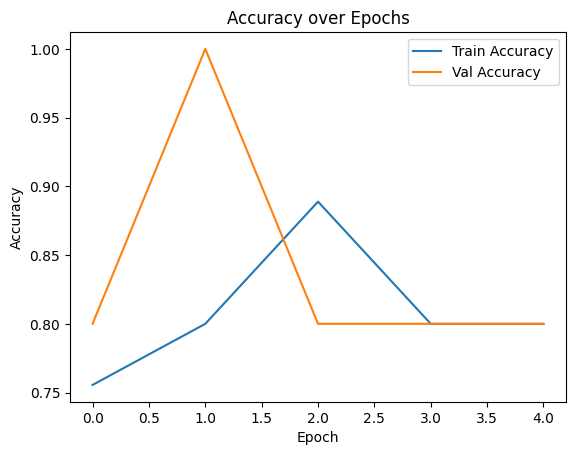

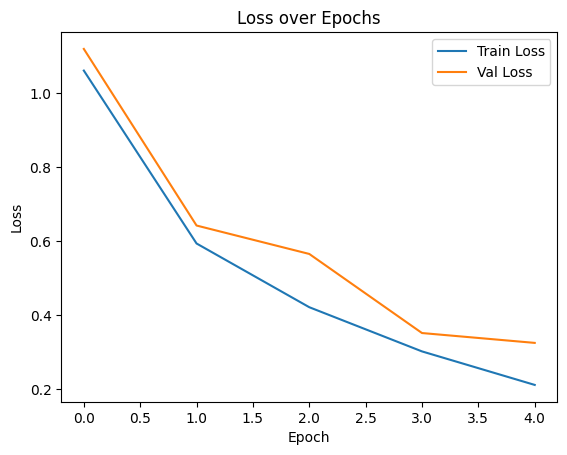

In [ ]:
import matplotlib.pyplot as plt

# Accuracy plot
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title("Accuracy over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Loss plot
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Loss over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
